In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lava18/google-play-store-apps")

print("Path to dataset files:", path)

C:\Users\majdz\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\majdz\.cache\kagglehub\datasets\lava18\google-play-store-apps\versions\6


## Data Loading and Initial Inspection

In [2]:
import pandas as pd 
import numpy as np
apps_df = pd.read_csv(r'C:\internship_oasis_online\OIBSIP\DataAnalytics-L1-UnveilingtheAndroidAppMarket(GooglePlayStoreAnalysis)\data\googleplaystore.csv')
reviews_df = pd.read_csv(r'C:\internship_oasis_online\OIBSIP\DataAnalytics-L1-UnveilingtheAndroidAppMarket(GooglePlayStoreAnalysis)\data\googleplaystore_user_reviews.csv')

In [3]:
apps_df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [4]:
reviews_df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [5]:
apps_df.shape

(10841, 13)

In [6]:
reviews_df.shape

(64295, 5)

In [7]:
apps_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [8]:
reviews_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 2.5 MB


In [9]:
apps_df.duplicated().sum()

np.int64(483)

In [10]:
reviews_df.duplicated().sum()

np.int64(33616)

In [11]:
apps_df[apps_df.duplicated()].head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.2,80805,Varies with device,"5,000,000+",Free,0,Everyone,Business,"February 26, 2018",Varies with device,4.0.3 and up
236,Box,BUSINESS,4.2,159872,Varies with device,"10,000,000+",Free,0,Everyone,Business,"July 31, 2018",Varies with device,Varies with device
239,Google My Business,BUSINESS,4.4,70991,Varies with device,"5,000,000+",Free,0,Everyone,Business,"July 24, 2018",2.19.0.204537701,4.4 and up
256,ZOOM Cloud Meetings,BUSINESS,4.4,31614,37M,"10,000,000+",Free,0,Everyone,Business,"July 20, 2018",4.1.28165.0716,4.0 and up
261,join.me - Simple Meetings,BUSINESS,4.0,6989,Varies with device,"1,000,000+",Free,0,Everyone,Business,"July 16, 2018",4.3.0.508,4.4 and up


In [12]:
reviews_df[reviews_df.duplicated()].head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
7,10 Best Foods for You,NaN,NaN,NaN,NaN
15,10 Best Foods for You,NaN,NaN,NaN,NaN
78,10 Best Foods for You,Good,Positive,0.7,0.600000
79,10 Best Foods for You,Good,Positive,0.7,0.600000
100,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.0,0.533333


In [13]:
apps_bef = len(apps_df)
reviews_bef = len(reviews_df)
apps_df = apps_df.drop_duplicates()
reviews_df = reviews_df.drop_duplicates()
apps_df.shape

(10358, 13)

In [14]:
reviews_df.shape

(30679, 5)

In [15]:
apps_df.duplicated().sum()

np.int64(0)

In [16]:
reviews_df.duplicated().sum()

np.int64(0)

In [17]:
apps_df.isna().sum()

App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [18]:
reviews_df.isna().sum()

App                         0
Translated_Review         987
Sentiment                 982
Sentiment_Polarity        982
Sentiment_Subjectivity    982
dtype: int64

In [19]:
apps_df['Rating'].max()

np.float64(19.0)

In [20]:
apps_df['Rating'].min()

np.float64(1.0)

In [21]:
apps_df['Rating'].mean()

np.float64(4.18954233666929)

In [22]:
apps_df['Rating'].median()

np.float64(4.3)

In [23]:
apps_df[apps_df['Rating']>5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [24]:
apps_df.loc[10470:10474]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10470,Jazz Wi-Fi,COMMUNICATION,3.4,49,4.0M,"10,000+",Free,0,Everyone,Communication,"February 10, 2017",0.1,2.3 and up
10471,Xposed Wi-Fi-Pwd,PERSONALIZATION,3.5,1042,404k,"100,000+",Free,0,Everyone,Personalization,"August 5, 2014",3.0.0,4.0.3 and up
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN
10473,osmino Wi-Fi: free WiFi,TOOLS,4.2,134203,4.1M,"10,000,000+",Free,0,Everyone,Tools,"August 7, 2018",6.06.14,4.4 and up
10474,Sat-Fi Voice,COMMUNICATION,3.4,37,14M,"1,000+",Free,0,Everyone,Communication,"November 21, 2014",2.2.1.5,2.2 and up


In [25]:
apps_df.loc[10472] = [   "Life Made WI-Fi Touchscreen Photo Frame",
    np.nan,
    1.9,
    "19",
    "3.0M",
    "1,000+",
    "Free",
    "0",
    "Everyone",
    np.nan,
    "February 11, 2018",
    "1.0.19",
    "4.0 and up"
]

In [26]:
apps_df.loc[10472]

App               Life Made WI-Fi Touchscreen Photo Frame
Category                                              NaN
Rating                                                1.9
Reviews                                                19
Size                                                 3.0M
Installs                                           1,000+
Type                                                 Free
Price                                                   0
Content Rating                                   Everyone
Genres                                                NaN
Last Updated                            February 11, 2018
Current Ver                                        1.0.19
Android Ver                                    4.0 and up
Name: 10472, dtype: object

In [27]:
apps_df['Rating'].max()

np.float64(5.0)

In [28]:
apps_df[apps_df['Rating'].isna()]['Reviews'].describe()

count     1465
unique     100
top          0
freq       593
Name: Reviews, dtype: object

In [29]:
apps_df['Reviews'].dtype

<StringDtype(storage='python', na_value=nan)>

In [30]:
apps_df['Reviews'].str.isnumeric().value_counts()

Reviews
True    10358
Name: count, dtype: int64

In [31]:
apps_df['Reviews'] = pd.to_numeric(apps_df['Reviews'])  

In [32]:
apps_df['Reviews'].dtype

dtype('int64')

In [33]:
apps_df[apps_df['Rating'].isna() & (apps_df['Reviews'] > 0)].shape

(872, 13)

In [34]:
apps_df[apps_df['Rating'].isna() & (apps_df['Reviews'] > 0)].describe()

,Rating,Reviews
count,0.0,872.000000
mean,NaN,30.498853
std,NaN,180.902965
min,NaN,1.000000
25%,NaN,2.000000
50%,NaN,4.000000
75%,NaN,11.000000
max,NaN,3248.000000


In [35]:
apps_df['Type'].value_counts()

Type
Free    9592
Paid     765
Name: count, dtype: int64

In [36]:
apps_df[apps_df['Type'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [37]:
apps_df.loc[9146:9150]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9146,The Simpsons™: Tapped Out,FAMILY,4.3,636995,49M,"10,000,000+",Free,0,Teen,Casual,"July 31, 2018",4.34.0,4.0.3 and up
9147,Plants vs. Zombies™ 2,FAMILY,4.4,567632,15M,"10,000,000+",Free,0,Everyone 10+,Casual,"June 12, 2018",6.8.1,4.1 and up
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device
9149,Star Wars™: Galaxy of Heroes,FAMILY,4.5,1461698,67M,"10,000,000+",Free,0,Everyone 10+,Role Playing,"May 21, 2018",0.12.334385,4.1 and up
9150,Dungeon Keeper,FAMILY,4.0,69574,45M,"500,000+",Free,0,Everyone 10+,Strategy,"May 24, 2018",1.8.91,4.1 and up


In [38]:
apps_df.loc[9148 ,['Type' , 'Price']]

Type     NaN
Price      0
Name: 9148, dtype: str

In [39]:
apps_df.loc[9148 , 'Type'] = 'Free'

In [40]:
apps_df.loc[9148 , 'Type'] 

'Free'

In [41]:
apps_df['Type'].isna().sum()

np.int64(0)

In [42]:
apps_df[apps_df['Content Rating'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [43]:
apps_df.isna().sum()

App                  0
Category             1
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               1
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64

In [44]:
apps_df.loc[10472]

App               Life Made WI-Fi Touchscreen Photo Frame
Category                                              NaN
Rating                                                1.9
Reviews                                                19
Size                                                 3.0M
Installs                                           1,000+
Type                                                 Free
Price                                                   0
Content Rating                                   Everyone
Genres                                                NaN
Last Updated                            February 11, 2018
Current Ver                                        1.0.19
Android Ver                                    4.0 and up
Name: 10472, dtype: object

In [45]:
apps_df[apps_df['App'] == 'Life Made WI-Fi Touchscreen Photo Frame']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,NaN,1.9,19,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up


In [46]:
apps_df[apps_df['Current Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.2,55,2.7M,"5,000+",Free,0,Everyone,Art & Design,"June 6, 2018",NaN,4.2 and up
1553,Market Update Helper,LIBRARIES_AND_DEMO,4.1,20145,11k,"1,000,000+",Free,0,Everyone,Libraries & Demo,"February 12, 2013",NaN,1.5 and up
6322,Virtual DJ Sound Mixer,TOOLS,4.2,4010,8.7M,"500,000+",Free,0,Everyone,Tools,"May 10, 2017",NaN,4.0 and up
6803,BT Master,FAMILY,NaN,0,222k,100+,Free,0,Everyone,Education,"November 6, 2016",NaN,1.6 and up
7333,Dots puzzle,FAMILY,4.0,179,14M,"50,000+",Paid,$0.99,Everyone,Puzzle,"April 18, 2018",NaN,4.0 and up
7407,Calculate My IQ,FAMILY,NaN,44,7.2M,"10,000+",Free,0,Everyone,Entertainment,"April 3, 2017",NaN,2.3 and up
7730,UFO-CQ,TOOLS,NaN,1,237k,10+,Paid,$0.99,Everyone,Tools,"July 4, 2016",NaN,2.0 and up
10342,La Fe de Jesus,BOOKS_AND_REFERENCE,NaN,8,658k,"1,000+",Free,0,Everyone,Books & Reference,"January 31, 2017",NaN,3.0 and up


In [47]:
apps_df[apps_df['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11M,"1,000+",Paid,$1.49,Everyone,Personalization,"July 20, 2018",4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2.1M,"10,000+",Free,0,Everyone,Personalization,"March 27, 2018",1.1,NaN


In [48]:
apps_df.isna().sum()

App                  0
Category             1
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               1
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64

In [49]:
apps_df['Installs'].dtype

<StringDtype(storage='python', na_value=nan)>

In [50]:
apps_df['Installs'].value_counts().head(20)


Installs
1,000,000+        1488
10,000,000+       1132
100,000+          1129
10,000+           1033
1,000+             891
100+               710
5,000,000+         683
500,000+           517
50,000+            474
5,000+             469
10+                385
100,000,000+       369
500+               328
50,000,000+        272
50+                204
5+                  82
1+                  67
500,000,000+        61
1,000,000,000+      49
0+                  14
Name: count, dtype: int64

In [51]:
apps_df['Installs'] = apps_df['Installs'].str.replace('+', '')

In [52]:
apps_df['Installs'] = apps_df['Installs'].str.replace(',', '')

In [53]:
apps_df['Installs'] = pd.to_numeric(apps_df['Installs'])

In [54]:
apps_df['Installs'].dtype

dtype('int64')

In [55]:
apps_df['Installs'].head()

0       10000
1      500000
2     5000000
3    50000000
4      100000
Name: Installs, dtype: int64

In [56]:
apps_df['Size'].value_counts().head(20)

Size
Varies with device    1526
11M                    188
12M                    186
13M                    186
14M                    182
15M                    174
17M                    155
26M                    145
16M                    143
19M                    135
10M                    133
25M                    131
20M                    131
21M                    130
24M                    129
18M                    124
23M                    109
22M                    108
29M                     95
27M                     94
Name: count, dtype: int64

In [57]:
apps_df['Size'].str.contains('k', case=False, na=False).sum()

np.int64(315)

In [58]:
apps_df[apps_df['Size'].str.contains('k', case=False, na=False)]['Size'].value_counts().head(20)

Size
201k    3
79k     3
118k    3
266k    3
375k    3
18k     2
334k    2
318k    2
58k     2
196k    2
51k     2
26k     2
17k     2
172k    2
206k    2
473k    2
70k     2
842k    2
417k    2
335k    2
Name: count, dtype: int64

In [59]:
apps_df['Size'] = apps_df['Size'].replace('Varies with device' , np.nan)

In [60]:
apps_df['Size'].isna().sum()

np.int64(1526)

In [61]:
apps_df['Size'].str.endswith('M', na=False).sum()

np.int64(8517)

In [62]:
apps_df['Size'] = apps_df['Size'].str.replace('M', '')

In [63]:
apps_df['Size'].str.endswith('k', na=False).sum()

np.int64(315)

In [64]:
k_mask = apps_df['Size'].str.endswith('k', na=False)
apps_df['Size_MB'] = pd.to_numeric(apps_df['Size'], errors='coerce')

apps_df.loc[k_mask, 'Size_MB'] = (
    pd.to_numeric(apps_df.loc[k_mask, 'Size'].str.replace('k', '')) / 1024
)

In [65]:
apps_df[['Size', 'Size_MB']].head(10)

,Size,Size_MB
0,19,19.0
1,14,14.0
2,8.7,8.7
3,25,25.0
4,2.8,2.8
5,5.6,5.6
6,19,19.0
7,29,29.0
8,33,33.0
9,3.1,3.1


In [66]:
apps_df['Size_MB'].dtype


dtype('float64')

In [67]:
apps_df['Size_MB'].isna().sum()

np.int64(1526)

In [68]:
apps_df.loc[k_mask, ['Size', 'Size_MB']]

,Size,Size_MB
58,201k,0.196289
209,23k,0.022461
384,79k,0.077148
450,118k,0.115234
458,695k,0.678711
...,...,...
10763,552k,0.539062
10764,885k,0.864258
10798,1020k,0.996094
10832,582k,0.568359


In [69]:
apps_df['Size_MB'].describe()

count    8832.000000
mean       21.285343
std        22.540155
min         0.008301
25%         4.700000
50%        13.000000
75%        29.000000
max       100.000000
Name: Size_MB, dtype: float64

In [70]:
apps_df['Price'].value_counts().head(15)

Price
0          9593
$0.99       146
$2.99       125
$1.99        73
$4.99        70
$3.99        60
$1.49        46
$5.99        27
$2.49        25
$9.99        19
$6.99        12
$399.99      12
$14.99        9
$4.49         9
$7.99         7
Name: count, dtype: int64

In [71]:
apps_df['Price'] = apps_df['Price'].str.replace('$', '', regex=False)

In [72]:
apps_df['Price'].str.contains('$', regex=False).sum()

np.int64(0)

In [73]:
apps_df['Price'] = pd.to_numeric(apps_df['Price'])

In [74]:
apps_df['Price'].dtype

dtype('float64')

In [75]:
apps_df['Price'].describe()

count    10358.000000
mean         1.030701
std         16.277843
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        400.000000
Name: Price, dtype: float64

In [76]:
apps_df.groupby('Price')['Type'].describe()

,count,unique,top,freq
Price,,,,
0.00,9593,1,Free,9593
0.99,146,1,Paid,146
1.00,3,1,Paid,3
1.04,1,1,Paid,1
1.20,1,1,Paid,1
...,...,...,...,...
379.99,1,1,Paid,1
389.99,1,1,Paid,1
394.99,1,1,Paid,1


In [77]:
apps_df[(apps_df['Type'] == 'Free') & (apps_df['Price'] > 0)].shape[0]

0

In [78]:
apps_df[(apps_df['Type'] == 'Paid') & (apps_df['Price'] == 0)].shape[0]

0

In [79]:
apps_df[apps_df['Genres'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
10472,Life Made WI-Fi Touchscreen Photo Frame,NaN,1.9,19,3.0,1000,Free,0.0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,3.0


In [80]:
apps_df[apps_df['Current Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.2,55,2.7,5000,Free,0.00,Everyone,Art & Design,"June 6, 2018",NaN,4.2 and up,2.700000
1553,Market Update Helper,LIBRARIES_AND_DEMO,4.1,20145,11k,1000000,Free,0.00,Everyone,Libraries & Demo,"February 12, 2013",NaN,1.5 and up,0.010742
6322,Virtual DJ Sound Mixer,TOOLS,4.2,4010,8.7,500000,Free,0.00,Everyone,Tools,"May 10, 2017",NaN,4.0 and up,8.700000
6803,BT Master,FAMILY,NaN,0,222k,100,Free,0.00,Everyone,Education,"November 6, 2016",NaN,1.6 and up,0.216797
7333,Dots puzzle,FAMILY,4.0,179,14,50000,Paid,0.99,Everyone,Puzzle,"April 18, 2018",NaN,4.0 and up,14.000000
7407,Calculate My IQ,FAMILY,NaN,44,7.2,10000,Free,0.00,Everyone,Entertainment,"April 3, 2017",NaN,2.3 and up,7.200000
7730,UFO-CQ,TOOLS,NaN,1,237k,10,Paid,0.99,Everyone,Tools,"July 4, 2016",NaN,2.0 and up,0.231445
10342,La Fe de Jesus,BOOKS_AND_REFERENCE,NaN,8,658k,1000,Free,0.00,Everyone,Books & Reference,"January 31, 2017",NaN,3.0 and up,0.642578


In [81]:
apps_df['Current Ver'].isna().sum()

np.int64(8)

In [82]:
apps_df[apps_df['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11,1000,Paid,1.49,Everyone,Personalization,"July 20, 2018",4.4,NaN,11.0
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2.1,10000,Free,0.00,Everyone,Personalization,"March 27, 2018",1.1,NaN,2.1


In [83]:
apps_df.dtypes

App                   str
Category              str
Rating            float64
Reviews             int64
Size                  str
Installs            int64
Type                  str
Price             float64
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
Size_MB           float64
dtype: object

In [84]:
reviews_df.info()

<class 'pandas.DataFrame'>
Index: 30679 entries, 0 to 64236
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     30679 non-null  str    
 1   Translated_Review       29692 non-null  str    
 2   Sentiment               29697 non-null  str    
 3   Sentiment_Polarity      29697 non-null  float64
 4   Sentiment_Subjectivity  29697 non-null  float64
dtypes: float64(2), str(3)
memory usage: 1.4 MB


In [85]:
reviews_df[reviews_df['Translated_Review'].isna()].head(10)

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
2,10 Best Foods for You,NaN,NaN,NaN,NaN
268,11st,NaN,Neutral,0.0,0.0
362,1LINE – One Line with One Touch,NaN,NaN,NaN,NaN
405,2018Emoji Keyboard 😂 Emoticons Lite -sticker&gif,NaN,NaN,NaN,NaN
539,"2Date Dating App, Love and matching",NaN,NaN,NaN,NaN
628,2RedBeans,NaN,NaN,NaN,NaN
694,30 Day Fitness Challenge - Workout at Home,NaN,NaN,NaN,NaN
721,365Scores - Live Scores,NaN,NaN,NaN,NaN
760,3D Blue Glass Water Keyboard Theme,NaN,NaN,NaN,NaN
800,3D Color Pixel by Number - Sandbox Art Coloring,NaN,NaN,NaN,NaN


In [86]:
reviews_df = reviews_df.dropna(subset = ['Translated_Review'])

In [87]:
reviews_df.shape

(29692, 5)

In [88]:
reviews_df.isna().sum()

App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64

In [89]:
reviews_df['Sentiment'].value_counts()

Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64

In [90]:
reviews_df[['Sentiment_Polarity', 'Sentiment_Subjectivity']].describe()


,Sentiment_Polarity,Sentiment_Subjectivity
count,29692.000000,29692.000000
mean,0.188868,0.490930
std,0.355694,0.265976
min,-1.000000,0.000000
25%,0.000000,0.350000
50%,0.157143,0.514286
75%,0.422917,0.652703
max,1.000000,1.000000


In [91]:
reviews_df.groupby('Sentiment')['Sentiment_Polarity'].describe()

,count,mean,std,min,25%,50%,75%,max
Sentiment,,,,,,,,
Negative,6321.0,-0.263659,0.239739,-1.000000e+00,-0.383333,-0.1925,-0.083333,-2.523234e-18
Neutral,4356.0,0.000000,0.000000,0.000000e+00,0.000000,0.0000,0.000000,0.000000e+00
Positive,19015.0,0.382564,0.254340,5.551115e-18,0.177113,0.3500,0.525000,1.000000e+00


In [92]:
apps_df['Category'].value_counts()

Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
Name: count, dtype: int64

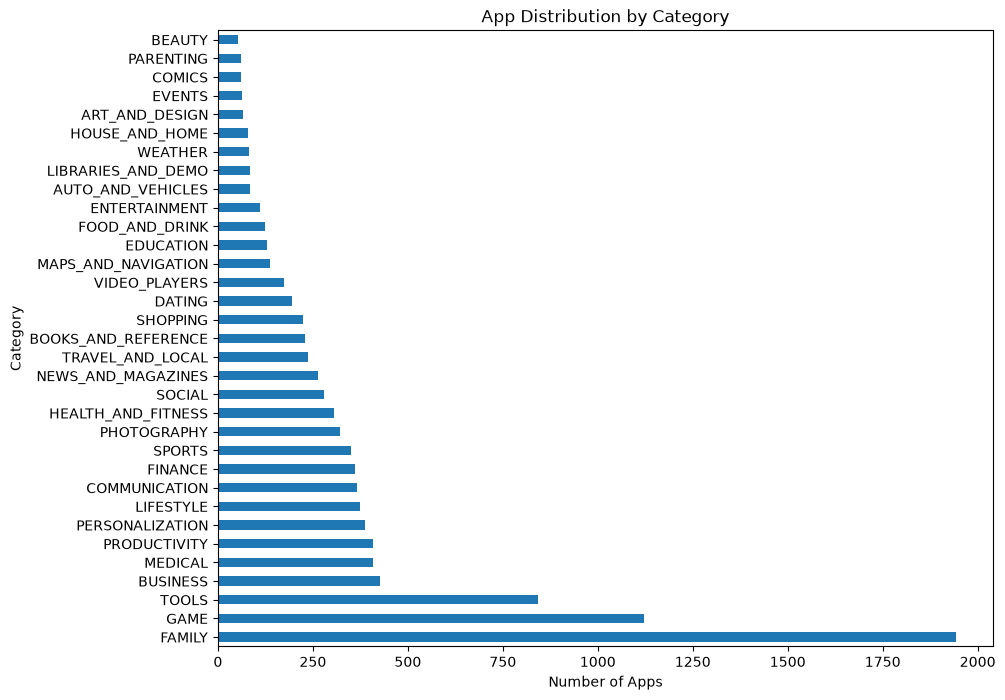

In [93]:
import matplotlib.pyplot as plt
apps_df['Category'].value_counts().plot(kind = 'barh' , title = 'App Distribution by Category' , figsize = (10 , 8))
plt.xlabel('Number of Apps')
plt.ylabel('Category')

plt.show()                                        

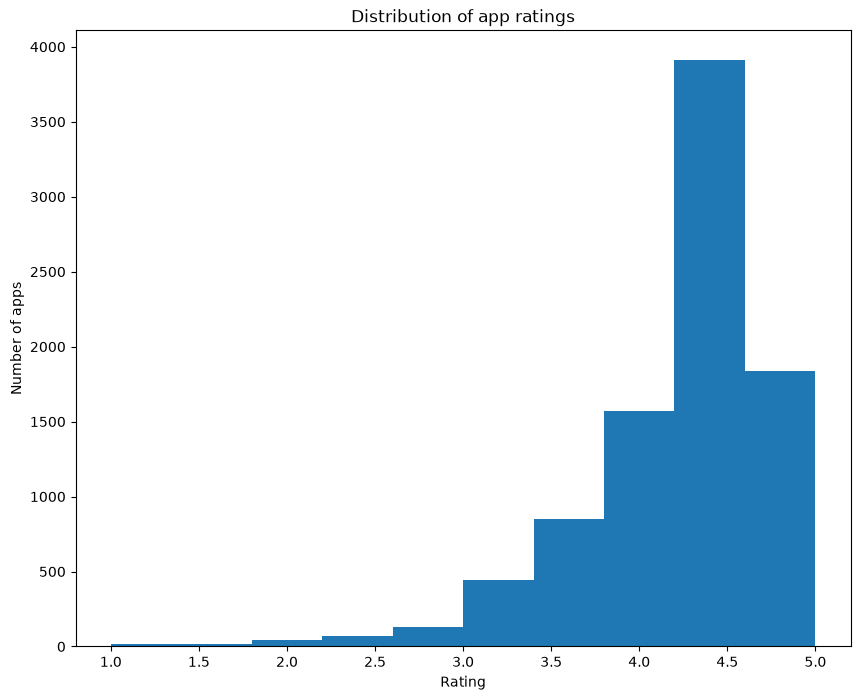

In [94]:
apps_df['Rating'].plot(kind = 'hist' , figsize = (10 , 8) , title = 'Distribution of app ratings')
plt.xlabel('Rating')
plt.ylabel('Number of apps')
plt.show()

In [96]:
apps_df.groupby('Category')['Rating'].mean()

Category
ART_AND_DESIGN         4.358065
AUTO_AND_VEHICLES      4.190411
BEAUTY                 4.278571
BOOKS_AND_REFERENCE    4.347458
BUSINESS               4.102593
COMICS                 4.155172
COMMUNICATION          4.151466
DATING                 3.971698
EDUCATION              4.375969
ENTERTAINMENT          4.136036
EVENTS                 4.435556
FAMILY                 4.191153
FINANCE                4.127445
FOOD_AND_DRINK         4.164151
GAME                   4.281285
HEALTH_AND_FITNESS     4.261450
HOUSE_AND_HOME         4.164706
LIBRARIES_AND_DEMO     4.178462
LIFESTYLE              4.096066
MAPS_AND_NAVIGATION    4.051613
MEDICAL                4.182450
NEWS_AND_MAGAZINES     4.128505
PARENTING              4.300000
PERSONALIZATION        4.333871
PHOTOGRAPHY            4.182895
PRODUCTIVITY           4.201796
SHOPPING               4.251485
SOCIAL                 4.254918
SPORTS                 4.225175
TOOLS                  4.047411
TRAVEL_AND_LOCAL       4.094146

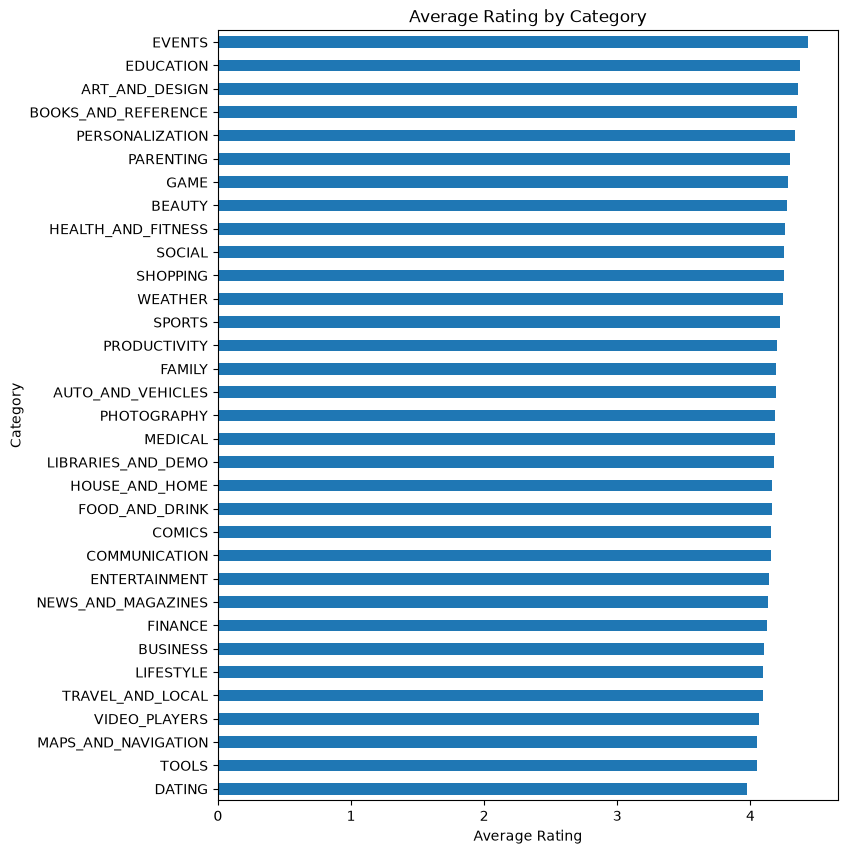

In [100]:
apps_df.groupby('Category')['Rating'].mean().sort_values().plot(kind = 'barh' , figsize = (8,10) , title = 'Average Rating by Category')
plt.xlabel('Average Rating')
plt.ylabel('Category')
plt.show()

In [102]:
Size_MB_cleaned = apps_df.dropna(subset = ['Size_MB'] )
Size_MB_cleaned.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19,10000,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,19.0
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14,500000,Free,0.0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7,5000000,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,8.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25,50000000,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,25.0
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8,100000,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,2.8


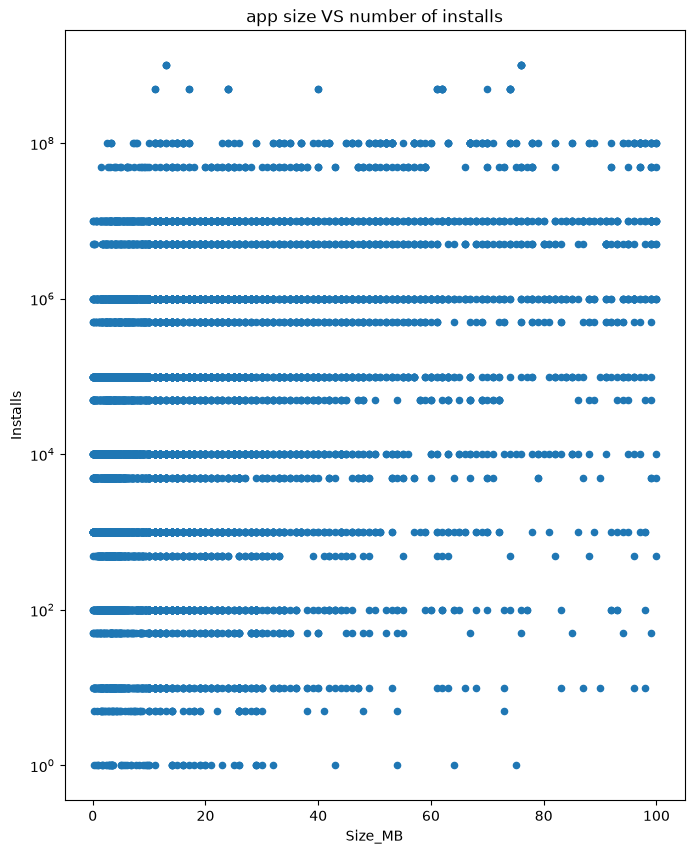

In [112]:
Size_MB_cleaned.plot(kind = 'scatter' ,x = 'Size_MB' ,y = 'Installs' , figsize = (8,10) , title = 'app size VS number of installs')
xlabel = 'size of app'
ylabel = 'nb of installs'
plt.yscale('log')
plt.show()

In [110]:
Size_MB_cleaned[['Size_MB', 'Installs']].corr()

,Size_MB,Installs
Size_MB,1.00000,0.16888
Installs,0.16888,1.00000


### Observation

- The scatter plot shows a weak relationship between app size and the number of installs.
- The correlation coefficient is **0.16888**, indicating a **weak positive correlation**.
- This suggests that larger apps tend to have slightly more installs, but **app size alone is not a strong predictor of app popularity**.
- Other factors, such as app category, quality, functionality, and user experience, are likely to have a greater influence on the number of installs.

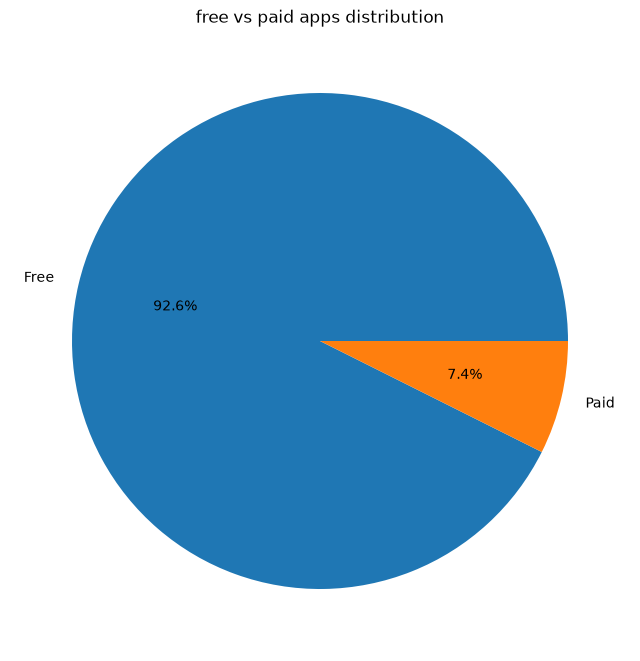

In [117]:
apps_df['Type'].value_counts().plot(kind = 'pie' , figsize = (8,10) , title = 'free vs paid apps distribution' , autopct = '%1.1f%%')
plt.show()

In [121]:
paid_df = apps_df[apps_df['Type'] == 'Paid']
paid_df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
234,TurboScan: scan documents and receipts in PDF,BUSINESS,4.7,11442,6.8,100000,Paid,4.99,Everyone,Business,"March 25, 2018",1.5.2,4.0 and up,6.8
235,Tiny Scanner Pro: PDF Doc Scan,BUSINESS,4.8,10295,39,100000,Paid,4.99,Everyone,Business,"April 11, 2017",3.4.6,3.0 and up,39.0
427,Puffin Browser Pro,COMMUNICATION,4.0,18247,NaN,100000,Paid,3.99,Everyone,Communication,"July 5, 2018",7.5.3.20547,4.1 and up,NaN
476,"Moco+ - Chat, Meet People",DATING,4.2,1545,NaN,10000,Paid,3.99,Mature 17+,Dating,"June 19, 2018",2.6.139,4.1 and up,NaN
477,Calculator,DATING,2.6,57,6.2,1000,Paid,6.99,Everyone,Dating,"October 25, 2017",1.1.6,4.0 and up,6.2


In [122]:
paid_df['Price'].describe()

count    765.000000
mean      13.955556
std       58.406966
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64

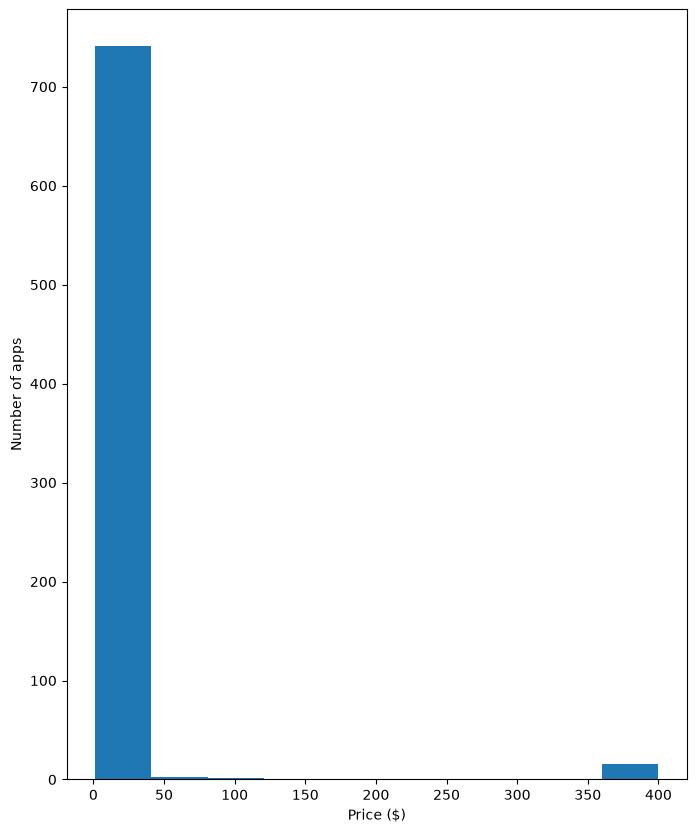

In [126]:
paid_df['Price'].plot(kind = 'hist' , figsize = (8,10) , title = 'distribution of prices per apps')
plt.xlabel('Price ($)')
plt.ylabel('Number of apps')
plt.show()

### Observation

- The analysis includes **765 paid apps**.
- The price distribution is **strongly right-skewed**, with most paid apps concentrated at relatively low prices.
- The median price is **$2.99**, while **75% of paid apps cost $4.99 or less**.
- The maximum price is **$400**, indicating the presence of a small number of high-priced apps.
- The mean price (**$13.96**) is substantially higher than the median because of these expensive outliers.

In [129]:
paid_df['Revenue'] = paid_df['Price'] * paid_df['Installs']
paid_df[['Category', 'Price', 'Installs', 'Revenue']].head()

,Category,Price,Installs,Revenue
234,BUSINESS,4.99,100000,499000.0
235,BUSINESS,4.99,100000,499000.0
427,COMMUNICATION,3.99,100000,399000.0
476,DATING,3.99,10000,39900.0
477,DATING,6.99,1000,6990.0


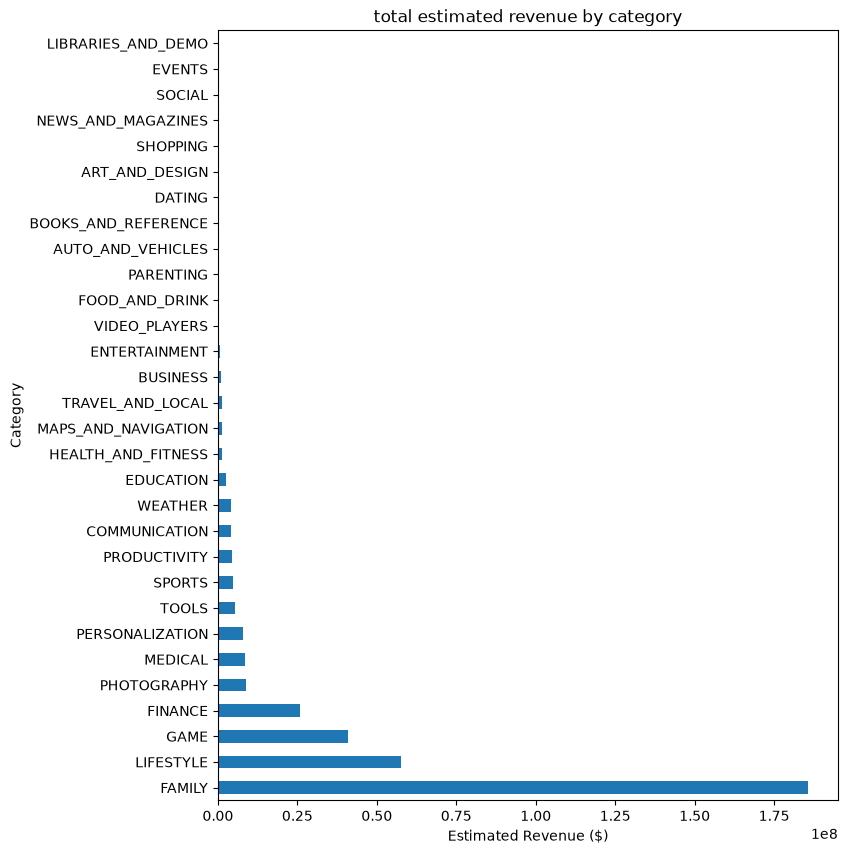

In [135]:
paid_df.groupby('Category')['Revenue'].sum().sort_values(ascending = False).plot(kind = 'barh' , figsize = (8,10) , title = 'total estimated revenue by category')
plt.xlabel('Estimated Revenue ($)')
plt.ylabel('Category')
plt.show()

In [141]:
reviews_df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
5,10 Best Foods for You,Best way,Positive,1.00,0.300000


In [138]:
reviews_df['Sentiment'].value_counts(dropna=False)

Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64

In [142]:
reviews_df.columns

Index(['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity',
       'Sentiment_Subjectivity'],
      dtype='str')

In [143]:
reviews_df['Sentiment'].value_counts(normalize=True).mul(100).round(2)

Sentiment
Positive    64.04
Negative    21.29
Neutral     14.67
Name: proportion, dtype: float64

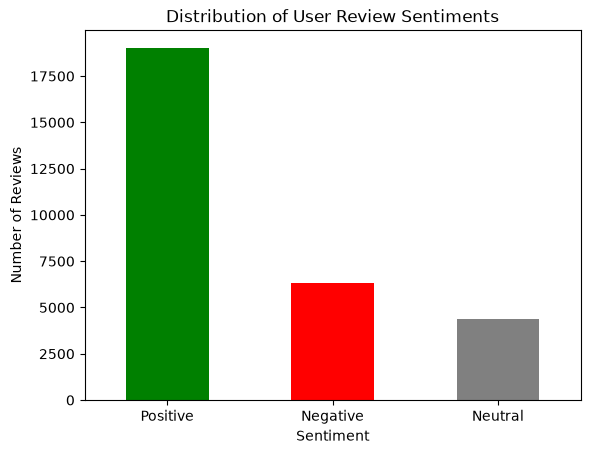

In [146]:
reviews_df['Sentiment'].value_counts().plot(kind='bar', color=['green', 'red', 'gray'])

plt.title('Distribution of User Review Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

### Sentiment Analysis — Key Observation

- **Positive reviews:** 64.04%
- **Negative reviews:** 21.29%
- **Neutral reviews:** 14.67%

Positive reviews represent the largest share of the dataset, suggesting generally favorable user feedback among the analyzed reviews. However, approximately 21% of reviews are negative, indicating opportunities for app developers to identify and address user dissatisfaction.

In [147]:
reviews_df['App'].isin(apps_df['App']).mean() * 100

np.float64(95.1434729893574)

In [148]:
reviews_with_category = reviews_df.merge(
    apps_df[['App', 'Category']].drop_duplicates(subset='App'),
    on='App',
    how='left'
)

In [149]:
reviews_with_category[['App', 'Category', 'Sentiment']].head()

,App,Category,Sentiment
0,10 Best Foods for You,HEALTH_AND_FITNESS,Positive
1,10 Best Foods for You,HEALTH_AND_FITNESS,Positive
2,10 Best Foods for You,HEALTH_AND_FITNESS,Positive
3,10 Best Foods for You,HEALTH_AND_FITNESS,Positive
4,10 Best Foods for You,HEALTH_AND_FITNESS,Positive


In [150]:
reviews_with_category['Category'].isna().sum()

np.int64(1442)

In [151]:
sentiment_by_category = pd.crosstab(
    reviews_with_category.dropna(subset=['Category'])['Category'],
    reviews_with_category.dropna(subset=['Category'])['Sentiment'],
    normalize='index'
) * 100

sentiment_by_category = sentiment_by_category.round(2)

sentiment_by_category.head()

Sentiment,Negative,Neutral,Positive
Category,,,
ART_AND_DESIGN,15.25,16.95,67.80
AUTO_AND_VEHICLES,6.01,12.72,81.27
BEAUTY,18.93,25.55,55.52
BOOKS_AND_REFERENCE,13.61,17.18,69.21
BUSINESS,17.50,24.81,57.69


In [152]:
print("Top 5 Categories by Positive Sentiment:")
print(sentiment_by_category['Positive'].sort_values(ascending=False).head(5))

print("\nTop 5 Categories by Negative Sentiment:")
print(sentiment_by_category['Negative'].sort_values(ascending=False).head(5))

Top 5 Categories by Positive Sentiment:
Category
COMICS                86.67
AUTO_AND_VEHICLES     81.27
EVENTS                78.85
HEALTH_AND_FITNESS    77.85
EDUCATION             75.78
Name: Positive, dtype: float64

Top 5 Categories by Negative Sentiment:
Category
GAME             35.47
SOCIAL           28.74
FAMILY           27.64
ENTERTAINMENT    25.76
VIDEO_PLAYERS    25.46
Name: Negative, dtype: float64


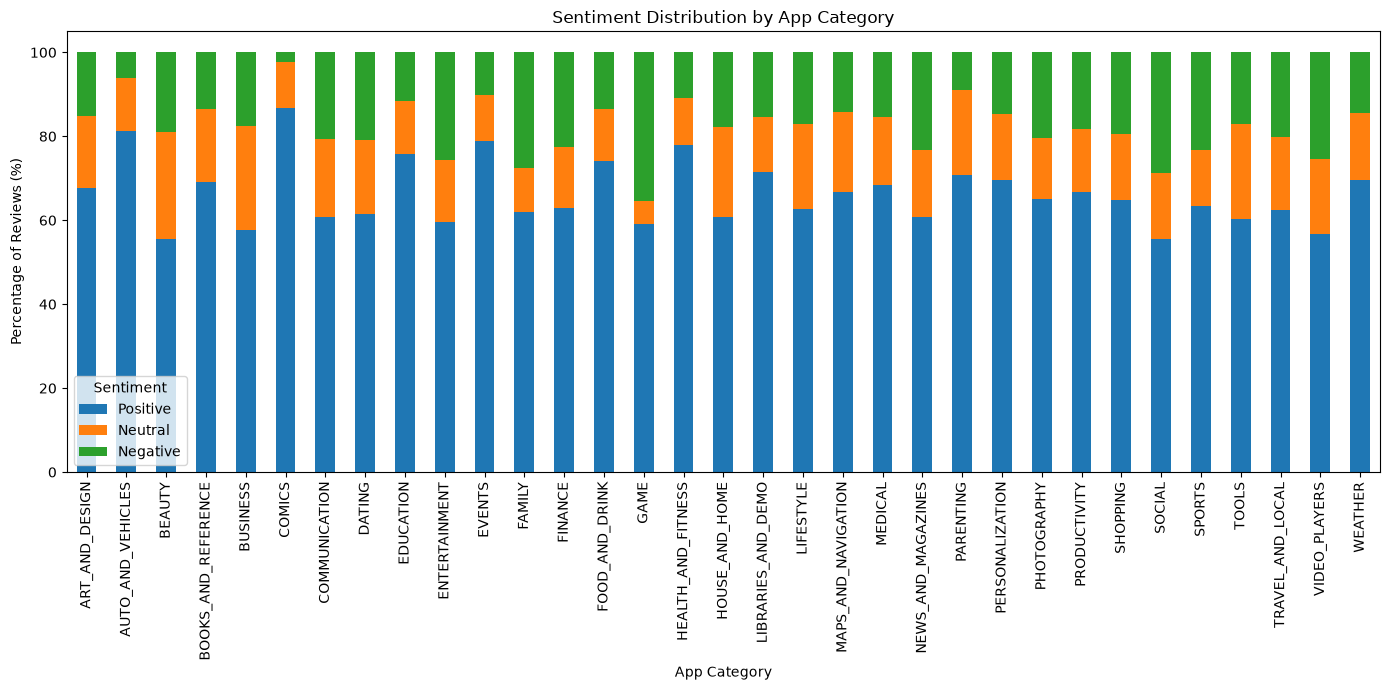

In [153]:
sentiment_by_category[['Positive', 'Neutral', 'Negative']].plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title('Sentiment Distribution by App Category')
plt.xlabel('App Category')
plt.ylabel('Percentage of Reviews (%)')
plt.xticks(rotation=90)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

## Conclusion and Business Recommendations

### Key Insights

1. **Positive user sentiment dominates the review dataset.** Approximately 64.04% of analyzed reviews are positive, compared with 21.29% negative and 14.67% neutral. Developers should focus on delivering a reliable user experience while investigating negative feedback to identify areas for improvement.

2. **Some categories show particularly positive user sentiment.** COMICS has the highest positive sentiment percentage at 86.67%, followed by AUTO_AND_VEHICLES at 81.27%. Developers can investigate successful apps in these categories to understand what users appreciate. However, sentiment alone does not establish market demand or profitability.

3. **Gaming apps have a relatively high proportion of negative reviews.** The GAME category has the highest negative sentiment percentage at 35.47%, followed by SOCIAL at 28.74%. Developers entering these categories should prioritize user testing, performance, usability, and ongoing feedback analysis to reduce dissatisfaction.

### Final Recommendation

Before launching a new app, developers should evaluate category demand, competition, ratings, install counts, pricing, and user feedback together. Positive sentiment can indicate user satisfaction, while negative sentiment can reveal opportunities for improvement. These findings should guide further market research rather than determine an app's potential success on their own.

*Note: Findings are based on the available datasets and may not represent all Google Play Store apps or users.*